# Sentence window vs. auto-merging: Advanced LlamaIndex RAG methods, head to head

LlamaIndex offers two strategies to equip the generation model with richer context beyond a single small chunk:

- **Sentence-window retrieval:** Documents are split into individual sentences and embedded for search. Each indexed sentence stores a surrounding context window (`window_size` on each side, default = 3). At query time, retrieved sentences are replaced with their stored context windows before generation, balancing precise retrieval with richer model context. 
  
- **Auto-merging retrieval:** Documents are organized into nested chunk hierarchies (e.g., 2048, 512 & 128 tokens). Search is performed on the smallest chunks, but when enough child chunks from the same larger parent chunk are retrieved, the parent chunk replaces them to provide broader context.

**Question:** Which method answers better on a document with known (ground truth) answers, and on which kinds of questions?

**Benchmark:** A fictional 25-page annual report (a company called Kerrowan Marine Systems plc) with 154 questions. Each has a
type, a reference answer and the exact evidence sentence(s), so retrieval can be checked without a (LLM/Jev) judge.

# II) SETUP

In [1]:
# Setup: install packages, start Ollama, load the models
import subprocess, sys, time, glob, json, re, logging, shutil, urllib.request

def sh(cmd, label):              # run quietly; show the output only if it fails
    print(label + "...")
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"{label} failed:\n{(r.stdout + r.stderr)[-2000:]}")

sh(f"{sys.executable} -m pip install -q llama-index-core==0.14.25 llama-index-llms-ollama==0.11.0 "
   "llama-index-embeddings-ollama==0.10.0 llama-index-readers-file==0.7.0 nest_asyncio pypdfium2",
   "Installing Python packages")
if shutil.which("ollama") is None:
    sh("apt-get update -qq && apt-get install -y -qq zstd", "Installing zstd")   # the Ollama installer needs it
    sh("curl -fsSL https://ollama.com/install.sh | sh", "Installing Ollama")
assert shutil.which("ollama"), "Ollama did not install. Is Internet switched on in the session options?"

subprocess.Popen("OLLAMA_CONTEXT_LENGTH=24576 OLLAMA_NUM_PARALLEL=1 OLLAMA_KEEP_ALIVE=-1 ollama serve > ollama.log 2>&1",
                 shell=True)
for _ in range(60):              # wait until the Ollama server answers
    try:
        urllib.request.urlopen("http://127.0.0.1:11434", timeout=2); break
    except Exception:
        time.sleep(1)
else:
    raise RuntimeError("The Ollama server did not start. Last lines of ollama.log:\n" + open("ollama.log").read()[-2000:])

LLM_MODEL, EMBED_MODEL = "qwen3.5:9b", "nomic-embed-text"
for m in (LLM_MODEL, EMBED_MODEL):
    sh(f"ollama pull {m}", f"Downloading {m}")

import nest_asyncio; nest_asyncio.apply()
logging.getLogger().setLevel(logging.WARNING)            # hide INFO lines from every library
for _name in ("httpx", "httpcore", "llama_index"):
    logging.getLogger(_name).setLevel(logging.WARNING)
import numpy as np, pandas as pd
from llama_index.llms.ollama import Ollama
from llama_index.embeddings.ollama import OllamaEmbedding
llm = Ollama(model=LLM_MODEL, context_window=24576, request_timeout=600, temperature=0, thinking=False)
embed = OllamaEmbedding(model_name=EMBED_MODEL, query_instruction="search_query: ",
                        text_instruction="search_document: ")
out = lambda cmd: subprocess.run(cmd, shell=True, capture_output=True, text=True).stdout.strip()
RUN_INFO = {"platform": "kaggle", "gpu": out("nvidia-smi --query-gpu=name --format=csv,noheader"),
            "ollama": out("ollama --version"), "models": out("ollama list")}   # recorded for reproducibility
print("Ready.", RUN_INFO["gpu"], "|", RUN_INFO["ollama"])

Installing Python packages...
Installing zstd...
Installing Ollama...
Ready. Tesla T4
Tesla T4 | ollama version is 0.40.7


## II) Document and Question Set

The 25 pages are merged into one document, so chunks and context windows can cross page breaks. All 154 questions are used: no parameters are tuned here, so there is no need to hold back a separate test set. The reader can find the zip file attached.


In [2]:
# 2. Load the report and the answer key
from llama_index.core import Document, SimpleDirectoryReader
pdf = glob.glob("/kaggle/input/**/kerrowan_annual_report_2025.pdf", recursive=True)[0]
key = json.load(open(glob.glob("/kaggle/input/**/answer_key.json", recursive=True)[0]))["questions"]
pages = SimpleDirectoryReader(input_files=[pdf]).load_data()
document = Document(text="\n\n".join(p.text for p in pages), id_="kerrowan")
QUESTIONS = key            # use key[::4] for a quick trial run
print(f"{len(pages)} pages, {len(document.text):,} characters, {len(QUESTIONS)} questions")
print(pd.Series([q["type"] for q in QUESTIONS]).value_counts().to_string())

25 pages, 61,659 characters, 154 questions
single              52
multihop_section    20
cross_section       20
near_duplicate      18
table               16
summary             12
unanswerable        10
superseded           6


## Page Overview

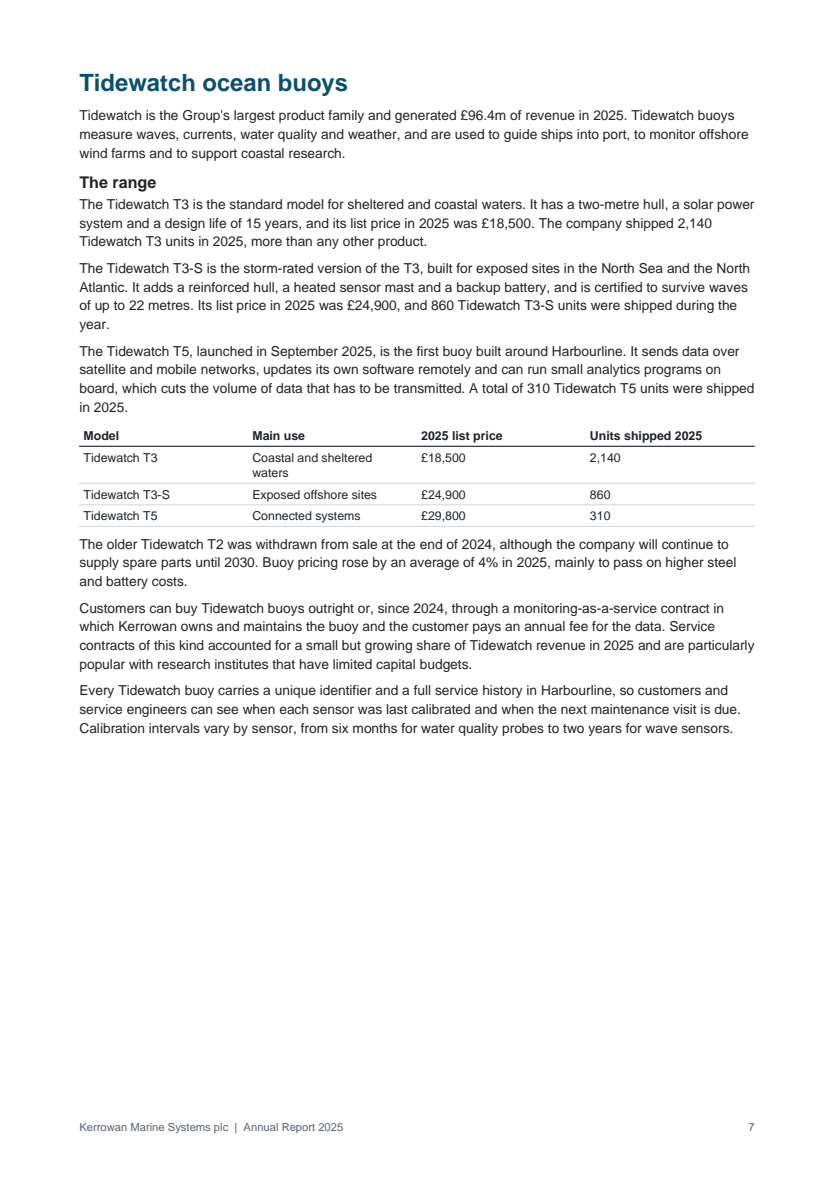

14 questions have their evidence on page 7, for example:
  [single] What is the design life of the Tidewatch T3?
      -> 15 years.
  [single] Up to what wave height is the Tidewatch T3-S certified to survive?
      -> Waves of up to 22 metres.
  [single] Until when will Kerrowan supply spare parts for the Tidewatch T2?
      -> Until 2030.
  [single] By how much did Tidewatch buoy prices rise on average in 2025?
      -> By an average of 4%.
  [table] What was the list price of the Tidewatch T5 in 2025?
      -> £29,800.
  [near_duplicate] How many Tidewatch T3 units were shipped in 2025?
      -> 2,140 units (the storm-rated T3-S shipped 860).
  [near_duplicate] How many Tidewatch T3-S units were shipped in 2025?
      -> 860 units.
  [near_duplicate] What was the list price of the Tidewatch T3 in 2025?
      -> £18,500.


In [3]:
import pypdfium2 as pdfium
from IPython.display import display
PAGE = 7
display(pdfium.PdfDocument(pdf)[PAGE - 1].render(scale=1.4).to_pil())
on_page = [q for q in key if PAGE in q["evidence_pages"]]
print(f"{len(on_page)} questions have their evidence on page {PAGE}, for example:")
for q in on_page[:8]:
    print(f"  [{q['type']}] {q['question']}\n      -> {q['answer']}")

## III) The RAG Systems

| System | Search unit | What the answering model sees |
|---|---|---|
| Basic RAG | 256-token chunks (overlap 30 tokens) | the 6 best chunks |
| Sentence window 1 / 3 / 5 | single sentences | the 6 best sentences, each with 1, 3 or 5 sentences on either side |
| Auto-merging 2048/512/128 | 128-token leaves | the 6 best leaves, merged into their parent when at least half its children match |
| Full context | none | the whole report (it fits in the model's context) |

These systems use the same LLM, the same embedding model, the same answer prompt and `top_k = 6`, which is the value in
LlamaIndex's auto-merging guide. Window size and the chunk-size ladder are each method's main knob. The
LlamaIndex/TruLens course also adds a reranker to sentence window; it is left out here so the two methods
are compared on retrieval alone.

In [4]:
# Build the systems
from llama_index.core import VectorStoreIndex, StorageContext, PromptTemplate
from llama_index.core.node_parser import (SentenceSplitter, SentenceWindowNodeParser, HierarchicalNodeParser,
                                          get_leaf_nodes)
from llama_index.core.postprocessor import MetadataReplacementPostProcessor
from llama_index.core.retrievers import AutoMergingRetriever
from llama_index.core.query_engine import RetrieverQueryEngine

TOP_K = 6
QA_PROMPT = PromptTemplate(
    "Context:\n{context_str}\n\nAnswer the question briefly, using only the context above. "
    "If the answer is not in the context, say that the report does not say.\nQuestion: {query_str}\nAnswer: ")

def basic_rag(chunk_size):
    nodes = SentenceSplitter(chunk_size=chunk_size, chunk_overlap = 30).get_nodes_from_documents([document])
    index = VectorStoreIndex(nodes, embed_model=embed)
    return index.as_query_engine(llm=llm, similarity_top_k=TOP_K, text_qa_template=QA_PROMPT)

def sentence_window(window_size):
    nodes = SentenceWindowNodeParser.from_defaults(window_size=window_size).get_nodes_from_documents([document])
    index = VectorStoreIndex(nodes, embed_model=embed)          # each node is one sentence
    return index.as_query_engine(llm=llm, similarity_top_k=TOP_K, text_qa_template=QA_PROMPT,
                                 node_postprocessors=[MetadataReplacementPostProcessor(target_metadata_key="window")])

def auto_merging(chunk_sizes):
    nodes = HierarchicalNodeParser.from_defaults(chunk_sizes=chunk_sizes).get_nodes_from_documents([document])
    storage = StorageContext.from_defaults(); storage.docstore.add_documents(nodes)
    index = VectorStoreIndex(get_leaf_nodes(nodes), storage_context=storage, embed_model=embed)
    retriever = AutoMergingRetriever(index.as_retriever(similarity_top_k=TOP_K), storage)  # merge at 0.5
    return RetrieverQueryEngine.from_args(retriever, llm=llm, text_qa_template=QA_PROMPT)

SYSTEMS = {
    "basic RAG": lambda: basic_rag(256),
    "sentence window 1": lambda: sentence_window(1),
    "sentence window 3": lambda: sentence_window(3),
    "sentence window 5": lambda: sentence_window(5),
    "auto-merging 2048/512/128": lambda: auto_merging([2048, 512, 128]),
    "full context": None,
}

## IV) Full Evaluation & Scoring

For each system and question we record:

- **Evidence Found**: The proportion of a question's evidence sentences that appear word-for-word in the text seen by the *answering* (i.e., `qwen3.5:9b`) model. Requires no LLM judge. (Unanswerable questions have no evidence and are skipped.)
  
- **Context Tokens & Seconds per Question:** Measures context size and execution speed. Providing more context yields more evidence, but increases latency and cost.

- **Correctness**: `CorrectnessEvaluator` compares the model's answer with the reference answer (passing threshold: $\ge 4/5$; LlamaIndex’s default).

- **Groundedness:** `FaithfulnessEvaluator` verifies that the answer is directly supported by the retrieved text. This is the one leg of the RAG triad that an answer key cannot replace. It is skipped for full-context runs, where the "retrieved text" encompasses the entire report and evaluating it would be too slow.

- **Answer Relevance & Context Relevance**: The remaining two legs of the RAG triad (`AnswerRelevancyEvaluator` and `ContextRelevancyEvaluator`), scored on a scale from 0 to 1. To optimize runtime, these are only evaluated for the head-to-head pair in TRIAD_SYSTEMS. Comparing context relevance against the exact evidence check reveals how reliable the RAG triad is when no ground-truth answer key is available.

In [5]:
# Answer, judge, save
import logging
logging.getLogger().setLevel(logging.WARNING)                # hide INFO lines from every library
for name in ("httpx", "httpcore", "llama_index"):
    logging.getLogger(name).setLevel(logging.WARNING)

from llama_index.core.evaluation import (CorrectnessEvaluator, FaithfulnessEvaluator,
                                         AnswerRelevancyEvaluator, ContextRelevancyEvaluator)
correctness, faithfulness = CorrectnessEvaluator(llm=llm), FaithfulnessEvaluator(llm=llm)
answer_relevancy, context_relevancy = AnswerRelevancyEvaluator(llm=llm), ContextRelevancyEvaluator(llm=llm)
TRIAD_SYSTEMS = {"sentence window 3", "auto-merging 2048/512/128"}   # full triad only here, to save time
norm = lambda s: re.sub(r"\s+", " ", s).strip()

def judge(evaluate, field="passing"):   # an unreadable judge reply counts as missing, not as wrong
    # Each judge call runs in its own short-lived event loop. Ollama's client would reuse a connection from the
    # previous (closed) loop, so every second judge call failed. A fresh async client per call fixes that.
    if hasattr(llm, "_async_client"):
        llm._async_client = None
    try:
        value = getattr(evaluate(), field)
        return np.nan if value is None else float(value)
    except Exception:
        return np.nan

rows = []
for name, make in SYSTEMS.items():
    t_system = time.time()
    engine = make() if make else None
    for q in QUESTIONS:
        t0 = time.time()
        if engine is None:
            response, contexts = None, [document.text]
            answer = llm.complete(QA_PROMPT.format(context_str=document.text, query_str=q["question"])).text
        else:
            response = engine.query(q["question"])
            answer, contexts = str(response), [n.node.get_content() for n in response.source_nodes]
        seconds = time.time() - t0
        seen = norm(" ".join(contexts))
        targets = [norm(e["text"]) for e in q["evidence"]]
        triad = response is not None and name in TRIAD_SYSTEMS
        rows.append({
            "system": name, "id": q["id"], "type": q["type"], "answer": answer,
            "found": sum(t in seen for t in targets) / len(targets) if targets else np.nan,
            "context_tokens": len(seen) / 4, "seconds": seconds,     # ~4 characters per token
            "correct": judge(lambda: correctness.evaluate(query=q["question"], response=answer, reference=q["answer"])),
            "grounded": judge(lambda: faithfulness.evaluate_response(response=response)) if response else np.nan,
            # triad scores are 0 to 1 (LlamaIndex divides the judge's raw score by its maximum)
            "answer_relevance": judge(lambda: answer_relevancy.evaluate(query=q["question"], response=answer),
                                      "score") if triad else np.nan,
            "context_relevance": judge(lambda: context_relevancy.evaluate(query=q["question"], contexts=contexts),
                                       "score") if triad else np.nan,
        })
    results = pd.DataFrame(rows); results.to_csv("results.csv", index=False)
    print(f"{name}: done in {(time.time() - t_system) / 60:.0f} min")

basic RAG: done in 25 min
sentence window 1: done in 18 min
sentence window 3: done in 117 min
sentence window 5: done in 27 min
auto-merging 2048/512/128: done in 127 min
full context: done in 18 min


## V) Results

**Summary:** one row per system. Intervals are 95% bootstrap intervals over questions, and **n** is the number of answers the judge scored
successfully (out of 154). Unreadable judge replies are left out, so a lower n means a less reliable score.

**Why answers failed:** each wrong answer to an answerable question is either a **retrieval failure** (the
evidence never reached the model) or a **generation failure** (the evidence was there, but the answer is
still wrong). This shows which half of a system to fix.

In [6]:
# Summary tables
rng = np.random.default_rng(0)
def ci(values):                 # mean and 95% bootstrap interval
    v = np.asarray(values, float); v = v[~np.isnan(v)]
    if len(v) == 0:
        return np.nan, np.nan, np.nan
    means = [rng.choice(v, len(v)).mean() for _ in range(2000)]
    return v.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)

def interval(values):           # mean, 95% interval and n = how many values the mean is based on
    m, lo, hi = ci(values)
    n = int(np.isfinite(np.asarray(values, float)).sum())
    return "n/a" if np.isnan(m) else f"{m:.2f} ({lo:.2f} to {hi:.2f}) n={n}"

order = list(SYSTEMS)
has_triad = "context_relevance" in results       # present if the triad was run
summary = pd.DataFrame({s: {
    "correct": interval(g["correct"]),
    "grounded": interval(g["grounded"]),
    **({"answer relevance": interval(g["answer_relevance"]),
        "context relevance": interval(g["context_relevance"])} if has_triad else {}),
    "evidence found": f"{g['found'].mean():.2f}",
    "context tokens": f"{g['context_tokens'].mean():.0f}",
    "seconds / question": f"{g['seconds'].mean():.1f}",
} for s, g in results.groupby("system")}).T.loc[order]
print(f"Summary (n = answers the judge scored successfully, out of {len(QUESTIONS)} per system)\n", summary.to_string())

by_type = results.groupby(["type", "system"])["correct"].mean().unstack()[order].round(2)
print("\nShare correct by question type\n", by_type.to_string())

answerable = results[results["type"] != "unanswerable"]
failures = pd.DataFrame({
    "correct": answerable.groupby("system")["correct"].mean(),
    "retrieval failure": answerable.assign(x=(answerable.correct == 0) & (answerable.found < 1)).groupby("system")["x"].mean(),
    "generation failure": answerable.assign(x=(answerable.correct == 0) & (answerable.found == 1)).groupby("system")["x"].mean(),
}).loc[order].round(2)
failures["unanswerable handled"] = results[results.type == "unanswerable"].groupby("system")["correct"].mean().round(2)
print("\nWhy answers failed (answerable questions; shares of all answers)\n", failures.to_string())

# Unreadable judge replies: the NAs that are not by design, per system
count_na = lambda s: s.isna().sum()
missing = pd.DataFrame({
    "correct": results.groupby("system")["correct"].apply(count_na),
    "grounded": results[results.system != "full context"].groupby("system")["grounded"].apply(count_na),
}).reindex(order)
if has_triad:                                         # the triad only ran for TRIAD_SYSTEMS
    triad_rows = results[results.system.isin(TRIAD_SYSTEMS)]
    for col in ["answer_relevance", "context_relevance"]:
        missing[col.replace("_", " ")] = triad_rows.groupby("system")[col].apply(count_na)
missing["answers"] = results.groupby("system").size()
print("\nUnreadable judge replies per system (<NA> = not measured for that system)\n",
      missing.astype("Int64").to_string())
print("Total unreadable judge replies:", int(missing.drop(columns="answers").sum().sum()))

Summary (n = answers the judge scored successfully, out of 154 per system)
                                              correct                   grounded           answer relevance          context relevance evidence found context tokens seconds / question
basic RAG                  0.85 (0.79 to 0.90) n=154  0.93 (0.89 to 0.97) n=154                        n/a                        n/a           0.72           1434                3.8
sentence window 1          0.84 (0.78 to 0.90) n=154  0.90 (0.84 to 0.94) n=154                        n/a                        n/a           0.77            625                2.0
sentence window 3          0.90 (0.86 to 0.94) n=154  0.94 (0.89 to 0.97) n=154  0.97 (0.95 to 0.99) n=154  0.85 (0.80 to 0.90) n=153           0.84           1444                3.2
sentence window 5          0.93 (0.88 to 0.97) n=154  0.94 (0.90 to 0.97) n=154                        n/a                        n/a           0.88           2231                4.0
auto-merg

# Hallucination checks (no LLM calls)

| Measure | How it is computed | Good value | What a high value means |
|---|---|---|---|
| **Answers unanswerable anyway** | Share of the 10 unanswerable questions where the answer contains no refusal phrase ("does not say", "not mentioned", …) | Close to 0 | The system invents answers when the report has none |
| **Refuses answerable questions** | Share of answerable questions where the answer *does* contain a refusal phrase | Close to 0 | Too cautious, or retrieval missed the evidence |
| **Not grounded (judge)** | 1 − share the groundedness judge marked as supported | Close to 0 | Claims the retrieved text doesn't support (judge-based, for comparison) |
| **Number not in report** | Share of lookup answers (single fact, table, near-duplicate) containing a number found nowhere in the report | Close to 0 | Made-up figures |

**Limits.** The refusal check matches phrases, so unusual wording is missed. The number check compares digits, so a
number the report writes in words ("Eighty-three ports") is flagged when an answer writes it as "83": check the
printed examples before counting them as hallucinations.

In [7]:
# Hallucination checks (no LLM calls)
REFUSAL = re.compile(r"does not (?:say|mention|state|specify|provide)|not (?:mentioned|stated|specified|provided|given|available)"
                     r"|no information|cannot be determined", re.I)
def numbers(text):
    return {n.replace(",", "").rstrip(".") for n in re.findall(r"\d[\d,]*(?:\.\d+)?", text)}
report_numbers = numbers(document.text)

r = results.copy()
r["refused"] = r.answer.str.contains(REFUSAL)
r["invented_number"] = r.answer.apply(lambda a: bool(numbers(a) - report_numbers))
lookups = r[r.type.isin(["single", "table", "near_duplicate"])]     # answers that should be copied, not computed

hallucination = pd.DataFrame({
    "answers unanswerable anyway": 1 - r[r.type == "unanswerable"].groupby("system").refused.mean(),
    "refuses answerable questions": r[r.type != "unanswerable"].groupby("system").refused.mean(),
    "not grounded (judge)": 1 - r.groupby("system").grounded.mean(),
    "number not in report": lookups.groupby("system").invented_number.mean(),
}).reindex(list(SYSTEMS)).round(2)
print(hallucination.to_string())
print("\nExamples of invented numbers:")
for _, x in lookups[lookups.invented_number].head(10).iterrows():
    print(f"  [{x.system}] {x.answer[:120]}")

caught = lookups[lookups.invented_number & lookups.grounded.notna()]
if len(caught):
    missed = (caught.grounded == 1).mean()
    print(f"\nAnswers with an invented number that the judge still called grounded: {missed:.0%} of {len(caught)}")

                           answers unanswerable anyway  refuses answerable questions  not grounded (judge)  number not in report
system                                                                                                                          
basic RAG                                          0.0                          0.19                  0.07                  0.01
sentence window 1                                  0.0                          0.20                  0.10                  0.00
sentence window 3                                  0.0                          0.10                  0.06                  0.01
sentence window 5                                  0.0                          0.09                  0.06                  0.00
auto-merging 2048/512/128                          0.0                          0.24                  0.10                  0.01
full context                                       0.0                          0.01             

## VI) Comparisons

auto-merging 2048/512/128 minus sentence window 3:
  correct         -0.11 (-0.18 to -0.05), 154 paired questions
  evidence found  -0.15 (-0.22 to -0.09), 144 paired questions


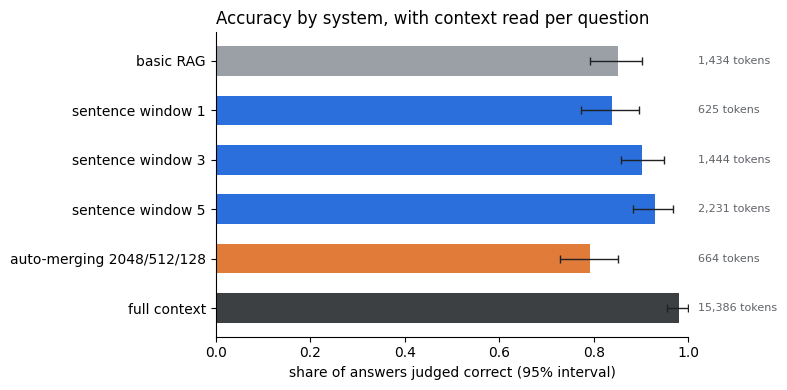

In [8]:
# 6. Paired comparison and the accuracy chart
a, b = "sentence window 3", "auto-merging 2048/512/128"
pair = results[results.system.isin([a, b])].pivot(index="id", columns="system", values=["correct", "found"])
print(f"{b} minus {a}:")
for label, d in [("correct", pair[("correct", b)] - pair[("correct", a)]),
                 ("evidence found", (pair[("found", b)] - pair[("found", a)]).dropna())]:
    m, lo, hi = ci(d)
    print(f"  {label:15s} {m:+.2f} ({lo:+.2f} to {hi:+.2f}), {d.notna().sum()} paired questions")

import matplotlib.pyplot as plt
FAMILY_COLORS = {"basic": "#9aa0a6", "sentence": "#2a6fdb", "auto-merging": "#e07b39", "full": "#3c4043"}
stats = [(name, *ci(results[results.system == name]["correct"]),
          results[results.system == name]["context_tokens"].mean()) for name in order]
fig, ax = plt.subplots(figsize=(8, 4))
for row, (name, m, lo, hi, tokens) in enumerate(stats):
    ax.barh(row, m, color=FAMILY_COLORS[name.split()[0]], height=0.6)
    ax.errorbar(m, row, xerr=[[m - lo], [hi - m]], color="#202124", capsize=3, linewidth=1)
    ax.text(1.02, row, f"{tokens:,.0f} tokens", va="center", fontsize=8, color="#5f6368",
            transform=ax.get_yaxis_transform())
ax.set_yticks(range(len(order)), order); ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.set_xlabel("share of answers judged correct (95% interval)")
ax.set_title("Accuracy by system, with context read per question", loc="left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig("accuracy_by_system.png", dpi=150); plt.show()

## VII) Export the best system

The best RAG system (highest share correct, full context excluded) is saved as `best_rag.zip`: its index (chunks,
windows and embeddings), its settings, the answer key and this run's answers. Load it anywhere with the same two
Ollama models, for example in production or in the Colab notebook `test_retest_colab.ipynb`, which checks whether
the judge and the system give the same results a second time.

In [9]:
# Export the best RAG system (index + settings + answer key + this run's answers)
import os
rag_only = results[results.system != "full context"]
scores = rag_only.groupby("system")["correct"].mean()
if scores.isna().all():                 # no correctness verdicts: fall back to evidence found
    scores = rag_only.groupby("system")["found"].mean()
best_name = scores.idxmax()
best = {"system": best_name, "top_k": TOP_K, "llm": LLM_MODEL, "embed_model": EMBED_MODEL,
        "qa_prompt": QA_PROMPT.template, "run_info": RUN_INFO}
if best_name.startswith("sentence window"):
    best.update(kind="sentence_window", window_size=int(best_name.split()[-1]))
    nodes = SentenceWindowNodeParser.from_defaults(window_size=best["window_size"]).get_nodes_from_documents([document])
    index = VectorStoreIndex(nodes, embed_model=embed)
elif best_name.startswith("auto-merging"):
    best.update(kind="auto_merging", chunk_sizes=[int(x) for x in best_name.split()[-1].split("/")])
    nodes = HierarchicalNodeParser.from_defaults(chunk_sizes=best["chunk_sizes"]).get_nodes_from_documents([document])
    storage = StorageContext.from_defaults(); storage.docstore.add_documents(nodes)
    index = VectorStoreIndex(get_leaf_nodes(nodes), storage_context=storage, embed_model=embed)
else:                              # basic RAG, same settings as in "Build the systems"
    best.update(kind="basic", chunk_size=256, chunk_overlap=30)
    nodes = SentenceSplitter(chunk_size=256, chunk_overlap=30).get_nodes_from_documents([document])
    index = VectorStoreIndex(nodes, embed_model=embed)

os.makedirs("best_rag", exist_ok=True)
index.storage_context.persist("best_rag/index")
json.dump(best, open("best_rag/config.json", "w"), indent=2)
json.dump({"questions": key}, open("best_rag/answer_key.json", "w"))
results[results.system == best_name].to_csv("best_rag/kaggle_results.csv", index=False)
shutil.make_archive("best_rag", "zip", "best_rag")
print(f"Exported '{best_name}' ({len(nodes)} nodes) to best_rag.zip")

Exported 'sentence window 5' (467 nodes) to best_rag.zip


# VIII) Summary

- **Correct vs. evidence found:** the failure table splits wrong answers into retrieval failures (evidence
  missing) and generation failures (evidence there, answer still wrong).
- **The chart:** same accuracy with less context means a cheaper, faster system.
- **n:** every judge score shows how many answers it rests on; a score with a much lower n is less reliable.

**Limitations**
- **The report fits in the model's context**, so full context is a reference point, not a fair competitor.
- **One short document, AI-written questions**: wording may overlap more than real users' questions would.
- **One model answers and judges**, so absolute scores depend on it. The judge was **not validated against human
  grades**; its consistency is checked separately by re-judging the same answers (`test_retest_colab.ipynb`).
- **Fixed `top_k = 6`, no reranker:** methods are compared on equal terms, not at their best. With only 6 hits,
  auto-merging rarely merges.